In [1]:
import pandas as pd

In [2]:
CD = "..//data//16_diecasting.csv"  # 샷·실린더압력·주조압력·사이클타임·비스킷두께·형체력·상태

In [3]:
df = pd.read_csv(CD)

In [4]:
# ── [개념] 분포의 폭 — 최소·최대·범위 ───────────────────────────────────────
# 형식: s.min() / s.max() / 범위 = max - min
# 왜: 범위가 비정상적으로 크면 이상 신호. 사이클타임 범위 6149초는 정상 주조로 불가능(설비 잼).

In [5]:
pd.set_option("display.precision",1)

In [6]:
df["사이클타임"].min()

np.float64(20.6)

In [8]:
df["사이클타임"].max()

np.float64(6170.0)

In [9]:
df["사이클타임"].max() - df["사이클타임"].min()

np.float64(6149.4)

In [11]:
pd.set_option("display.precision",2)

In [12]:
# ── [개념] 중심 — 평균 vs 중앙값 ────────────────────────────────────────────
# 왜: 평균은 이상치에 끌려가고 중앙값은 강하다. 둘의 큰 격차 자체가 이상치 신호.
print(df["사이클타임"].mean(), df["사이클타임"].median())  # 64.75 22.6

64.75 22.6


In [13]:
df.columns

Index(['샷', '실린더압력', '주조압력', '사이클타임', '비스킷두께', '형체력', '상태'], dtype='str')

In [14]:
# ── [개념] 사분위수 — quantile ──────────────────────────────────────────────
# 형식: s.quantile(0.25)=Q1, 0.5=Q2(중앙값), 0.75=Q3.  인자는 0~1 비율.
# 실수: quantile(25)처럼 25를 넣으면 오류 — 0.25로.

In [15]:
df["사이클타임"].quantile(0.25)

np.float64(20.8)

In [17]:
print(df["사이클타임"].quantile([0.25, 0.5, 0.75])) # [20.8, 22.6, 35.925]

0.25    20.80
0.50    22.60
0.75    35.92
Name: 사이클타임, dtype: float64


In [18]:
df["사이클타임"].median()

np.float64(22.6)

In [19]:
35.92 - 20.80

15.120000000000001

In [20]:
df["사이클타임"].describe()

count     188.00
mean       64.75
std       450.13
min        20.60
25%        20.80
50%        22.60
75%        35.92
max      6170.00
Name: 사이클타임, dtype: float64

In [21]:
print(df["사이클타임"].mean() -  df["사이클타임"].median()) 

42.15


In [23]:
# ── [개념] 분포 요약 — describe / 여러 컬럼 비교 ────────────────────────────
# describe: count·mean·std·min·25%·50%·75%·max 를 한 번에. mean과 50%(중앙값)의 격차로 이상치 감지.
df[["실린더압력", "비스킷두께", "형체력"]].quantile([0.25, 0.5, 0.75])

,실린더압력,비스킷두께,형체력
0.25,215.75,11.0,255.0
0.50,218.00,13.0,258.0
0.75,265.00,17.0,363.0


In [24]:
# ── [실습 1] 구조·분포 살펴보기 (주조 전체) ───────────────────────────────── 10시 22분

In [25]:
df = pd.read_csv(CD)
print(df.head())
print(df.shape)  # (202, 7)
print(df.columns.tolist())
df.info()

   샷  실린더압력    주조압력  사이클타임  비스킷두께    형체력  상태
0  1  214.0  1037.0   20.7   10.0  258.0   0
1  2  217.0  1052.0   20.7   11.0  257.0   0
2  3  214.0  1037.0   20.8   11.0  254.0   0
3  4  217.0  1052.0   20.6   11.0  253.0   0
4  5  217.0  1052.0   20.6   11.0  254.0   0
(202, 7)
['샷', '실린더압력', '주조압력', '사이클타임', '비스킷두께', '형체력', '상태']
<class 'pandas.DataFrame'>
RangeIndex: 202 entries, 0 to 201
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   샷       202 non-null    int64  
 1   실린더압력   188 non-null    float64
 2   주조압력    188 non-null    float64
 3   사이클타임   188 non-null    float64
 4   비스킷두께   188 non-null    float64
 5   형체력     188 non-null    float64
 6   상태      202 non-null    int64  
dtypes: float64(5), int64(2)
memory usage: 11.2 KB


In [27]:
# ── [실습 2] 한 컬럼의 최소·최대·범위 (실린더압력) ────────────────────────── 10시 27분

In [28]:
print(df["실린더압력"].min())  # 108.0
print(df["실린더압력"].max())  # 265.0
print(round(df["실린더압력"].max() - df["실린더압력"].min(), 1))  # 157.0

108.0
265.0
157.0


In [29]:
# ── [실습 3] 정렬해서 이상치 후보 찾기 (사이클타임) ───────────────────────── 10시 32분

In [31]:
정렬 = df.sort_values("사이클타임", ascending=False)
정렬[["샷", "사이클타임", "상태"]].head()
# 맨 위 6170초 = 설비 잼(상태 1). 100초 넘는 샷도 이상 후보. 정상 사이클은 20~35초 부근.

,샷,사이클타임,상태
199,200,6170.0,1
180,181,652.3,1
146,147,125.9,0
181,182,93.1,1
190,191,91.2,1


In [33]:
# 10분간 휴식후 11시 15분까지 실습 4 진행

In [34]:
print(round(df["사이클타임"].mean(), 2))  # 64.75 (이상치에 끌림)
print(df["사이클타임"].median())  # 22.6
정상 = df[df["상태"] == 0]
print(round(정상["사이클타임"].mean(), 2))  # 27.67 (중앙값에 근접)

64.75
22.6
27.67


In [35]:
# ── [실습 5] quantile로 Q1·Q2·Q3 (실린더압력) ───────────────11시 20분까지

In [36]:
# ── [실습 5] quantile로 Q1·Q2·Q3 (실린더압력) ───────────────────────────────
print(df["실린더압력"].quantile(0.25))  # 215.75 (Q1)
print(df["실린더압력"].quantile(0.5))  # 218.0  (Q2 = 중앙값)
print(df["실린더압력"].quantile(0.75))  # 265.0  (Q3)

215.75
218.0
265.0


In [37]:
# ── [실습 6] describe로 평균-중앙값 격차 큰 컬럼 찾기 ────────────────────────

In [38]:
# 전치

In [39]:
import numpy as np

In [40]:
np.array([[5,0,77,3],[9,1,41,12],[5,77,3,23]])

array([[ 5,  0, 77,  3],
       [ 9,  1, 41, 12],
       [ 5, 77,  3, 23]])

In [41]:
np.array([[5,0,77,3],[9,1,41,12],[5,77,3,23]]).T

array([[ 5,  9,  5],
       [ 0,  1, 77],
       [77, 41,  3],
       [ 3, 12, 23]])

In [44]:
np.array([[5,0,77,3],[9,1,41,12],[5,77,3,23]]).transpose()

array([[ 5,  9,  5],
       [ 0,  1, 77],
       [77, 41,  3],
       [ 3, 12, 23]])

In [42]:
pd.DataFrame(np.array([[5,0,77,3],[9,1,41,12],[5,77,3,23]]))

,0,1,2,3
0,5,0,77,3
1,9,1,41,12
2,5,77,3,23


In [43]:
pd.DataFrame(np.array([[5,0,77,3],[9,1,41,12],[5,77,3,23]])).T

,0,1,2
0,5,9,5
1,0,1,77
2,77,41,3
3,3,12,23


In [45]:
pd.DataFrame(np.array([[5,0,77,3],[9,1,41,12],[5,77,3,23]])).T.transpose()

,0,1,2,3
0,5,0,77,3
1,9,1,41,12
2,5,77,3,23


In [49]:
# 아래 실습은 전치 활용해보기

In [48]:
# # ── [실습 6] describe로 평균-중앙값 격차 큰 컬럼 찾기 ────11시 43분까지────────────────────

In [50]:
df[["실린더압력", "주조압력", "사이클타임", "비스킷두께", "형체력"]].describe()

,실린더압력,주조압력,사이클타임,비스킷두께,형체력
count,188.00,188.00,188.00,188.00,188.00
mean,234.31,848.70,64.75,14.17,303.11
std,32.12,244.73,450.13,3.66,56.16
min,108.00,255.00,20.60,2.00,222.00
25%,215.75,595.00,20.80,11.00,255.00
50%,218.00,1037.00,22.60,13.00,258.00
75%,265.00,1052.00,35.92,17.00,363.00
max,265.00,1159.00,6170.00,27.00,384.00


In [51]:
df[["실린더압력", "주조압력", "사이클타임", "비스킷두께", "형체력"]].describe().T

,count,mean,std,min,25%,50%,75%,max
실린더압력,188.0,234.31,32.12,108.0,215.75,218.0,265.00,265.0
주조압력,188.0,848.70,244.73,255.0,595.00,1037.0,1052.00,1159.0
사이클타임,188.0,64.75,450.13,20.6,20.80,22.6,35.92,6170.0
비스킷두께,188.0,14.17,3.66,2.0,11.00,13.0,17.00,27.0
형체력,188.0,303.11,56.16,222.0,255.00,258.0,363.00,384.0


In [52]:
요약 = df[["실린더압력", "주조압력", "사이클타임", "비스킷두께", "형체력"]].describe().T

In [53]:
요약["격차"] = (요약["mean"] - 요약["50%"]).abs()

In [54]:
요약

,count,mean,std,min,25%,50%,75%,max,격차
실린더압력,188.0,234.31,32.12,108.0,215.75,218.0,265.00,265.0,16.31
주조압력,188.0,848.70,244.73,255.0,595.00,1037.0,1052.00,1159.0,188.30
사이클타임,188.0,64.75,450.13,20.6,20.80,22.6,35.92,6170.0,42.15
비스킷두께,188.0,14.17,3.66,2.0,11.00,13.0,17.00,27.0,1.17
형체력,188.0,303.11,56.16,222.0,255.00,258.0,363.00,384.0,45.11


In [56]:
요약.sort_values("격차", ascending=False)[["mean", "50%", "max"]].head(3)

,mean,50%,max
주조압력,848.70,1037.0,1159.0
형체력,303.11,258.0,384.0
사이클타임,64.75,22.6,6170.0


In [57]:
# 주조압력·형체력·사이클타임: 평균-중앙값 격차 큰 이상치 의심 컬럼

In [61]:
# 1시 23분까지 실습7

In [63]:
q = df[["실린더압력", "사이클타임", "비스킷두께"]].quantile([0.25, 0.5, 0.75])

In [64]:
q

,실린더압력,사이클타임,비스킷두께
0.25,215.75,20.80,11.0
0.50,218.00,22.60,13.0
0.75,265.00,35.92,17.0


In [65]:
q.index

Index([0.25, 0.5, 0.75], dtype='float64')

In [66]:
q.loc[0.75]

실린더압력    265.00
사이클타임     35.92
비스킷두께     17.00
Name: 0.75, dtype: float64

In [67]:
q.loc[0.75] - q.loc[0.25]

실린더압력    49.25
사이클타임    15.12
비스킷두께     6.00
dtype: float64

In [ ]:
import pandas as pd

CD = '..//data//16_diecasting.csv'
WD = '..//data//16_welding.csv'

In [68]:
df = pd.read_csv(CD)

In [69]:
# ── [개념] IQR과 이상치 경계 ────────────────────────────────────────────────
# 형식: IQR = Q3 - Q1.  하한 = Q1 - 1.5*IQR,  상한 = Q3 + 1.5*IQR.
# 왜: 범위(max-min)는 이상치에 휘둘리지만, IQR은 가운데 절반이라 이상치에 강하다.
Q1 = df['실린더압력'].quantile(0.25)
Q3 = df['실린더압력'].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
print(IQR, lower, upper)     # 49.25 141.875 338.875

49.25 141.875 338.875


In [70]:
# 1시 50분까지 하시고 10분간 휴식 후 2시에 다시 진행

In [71]:
df.columns

Index(['샷', '실린더압력', '주조압력', '사이클타임', '비스킷두께', '형체력', '상태'], dtype='str')

In [72]:
Q1_cycle_time = df['사이클타임'].quantile(0.25)
Q3_cycle_time = df['사이클타임'].quantile(0.75)

In [73]:
Q1_cycle_time, Q3_cycle_time

(np.float64(20.8), np.float64(35.925))

In [74]:
# IQR
35.925 - 20.8

15.124999999999996

In [75]:
IQR_cycle_time = 35.925 - 20.8

In [76]:
상한 = Q3_cycle_time +  1.5*IQR_cycle_time
하한 = Q1_cycle_time -  1.5*IQR_cycle_time

In [77]:
상한,  하한

(np.float64(58.61249999999999), np.float64(-1.8874999999999922))

In [78]:
# ── [개념] 조건 필터로 이상치 골라내기 ──────────────────────────────────────
# 형식: mask = (열 < 하한) | (열 > 상한).  각 조건 괄호, '또는'은 | (and/or 금지).

In [80]:
lower, upper

(np.float64(141.875), np.float64(338.875))

In [81]:
mask = (df['실린더압력'] < lower) | (df['실린더압력'] > upper)

In [82]:
mask

0      False
1      False
2      False
3      False
4      False
       ...  
197     True
198    False
199     True
200    False
201    False
Name: 실린더압력, Length: 202, dtype: bool

In [86]:
df[mask]

,샷,실린더압력,주조압력,사이클타임,비스킷두께,형체력,상태
180,181,108.0,522.0,652.3,14.0,222.0,1
186,187,108.0,524.0,22.9,14.0,247.0,1
191,192,113.0,255.0,36.9,26.0,366.0,1
193,194,113.0,255.0,34.4,19.0,370.0,1
197,198,113.0,255.0,36.6,27.0,354.0,1
199,200,108.0,525.0,6170.0,15.0,237.0,1


In [ ]:
df[mask]['실린더압력']

180    108.0
186    108.0
191    113.0
193    113.0
197    113.0
199    108.0
Name: 실린더압력, dtype: float64

In [85]:
print(mask.sum(), round(mask.mean() * 100, 1))   # 6 3.0
# 이 6건은 모두 설비 이상 상태(상태 1) — 압력이 정상보다 낮게 튄 불량 샷.

6 3.0


In [ ]:
# 이 6건은 모두 설비 이상 상태(상태 1) — 압력이 정상보다 낮게 튄 불량 샷.

In [87]:
# ── [개념] 처리 3가지 — 제거 / clip 보정 / 결측변환+중앙값 ───────────────────

In [88]:
mask

0      False
1      False
2      False
3      False
4      False
       ...  
197     True
198    False
199     True
200    False
201    False
Name: 실린더압력, Length: 202, dtype: bool

In [89]:
~mask

0       True
1       True
2       True
3       True
4       True
       ...  
197    False
198     True
199    False
200     True
201     True
Name: 실린더압력, Length: 202, dtype: bool

In [90]:
df[~mask]

,샷,실린더압력,주조압력,사이클타임,비스킷두께,형체력,상태
0,1,214.0,1037.0,20.7,10.0,258.0,0
1,2,217.0,1052.0,20.7,11.0,257.0,0
2,3,214.0,1037.0,20.8,11.0,254.0,0
3,4,217.0,1052.0,20.6,11.0,253.0,0
4,5,217.0,1052.0,20.6,11.0,254.0,0
...,...,...,...,...,...,...,...
195,196,264.0,594.0,76.3,19.0,381.0,1
196,197,265.0,595.0,36.2,20.0,355.0,1
198,199,264.0,595.0,36.1,19.0,372.0,1
200,8,215.0,1038.0,20.9,11.0,258.0,0


In [91]:
df[~mask]['실린더압력']

0      214.0
1      217.0
2      214.0
3      217.0
4      217.0
       ...  
195    264.0
196    265.0
198    264.0
200    215.0
201    235.0
Name: 실린더압력, Length: 196, dtype: float64

In [93]:
print(round(df[~mask]['실린더압력'].mean(), 2))                 # 제거 238.39

238.39


In [96]:
df['실린더압력'].clip(lower, upper)

0      214.00
1      217.00
2      214.00
3      217.00
4      217.00
        ...  
197    141.88
198    264.00
199    141.88
200    215.00
201    235.00
Name: 실린더압력, Length: 202, dtype: float64

In [97]:
df['실린더압력'].clip(lower, upper).mean()

np.float64(235.30984042553192)

In [100]:
mask

0      False
1      False
2      False
3      False
4      False
       ...  
197     True
198    False
199     True
200    False
201    False
Name: 실린더압력, Length: 202, dtype: bool

In [101]:
sum(mask)

6

In [98]:
df['실린더압력'].mask(mask)

0      214.0
1      217.0
2      214.0
3      217.0
4      217.0
       ...  
197      NaN
198    264.0
199      NaN
200    215.0
201    235.0
Name: 실린더압력, Length: 202, dtype: float64

In [103]:
# 다시

In [104]:
import pandas as pd

CD = '..//data//16_diecasting.csv'
WD = '..//data//16_welding.csv'

df = pd.read_csv(CD)

In [ ]:
Q1 = df['실린더압력'].quantile(0.25)
Q3 = df['실린더압력'].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
print(IQR, lower, upper)     # 49.25 141.875 338.875

In [105]:
mask = (df['실린더압력'] < lower) | (df['실린더압력'] > upper)

In [106]:
print(mask.sum(), round(mask.mean() * 100, 1))   # 6 3.0

6 3.0


In [107]:
df[mask]

,샷,실린더압력,주조압력,사이클타임,비스킷두께,형체력,상태
180,181,108.0,522.0,652.3,14.0,222.0,1
186,187,108.0,524.0,22.9,14.0,247.0,1
191,192,113.0,255.0,36.9,26.0,366.0,1
193,194,113.0,255.0,34.4,19.0,370.0,1
197,198,113.0,255.0,36.6,27.0,354.0,1
199,200,108.0,525.0,6170.0,15.0,237.0,1


In [108]:
df['실린더압력'].mask(mask)

0      214.0
1      217.0
2      214.0
3      217.0
4      217.0
       ...  
197      NaN
198    264.0
199      NaN
200    215.0
201    235.0
Name: 실린더압력, Length: 202, dtype: float64

In [131]:
df['실린더압력'].mask(mask).isna().sum()

np.int64(20)

In [133]:
df['실린더압력'].isna().sum()

np.int64(14)

In [132]:
# 원래 결측치 14건에다가 mask로 이상치 true로 된 6건 합

In [ ]:
df

In [111]:
_m = df['실린더압력'].mask(mask)

In [112]:
print(round(_m.fillna(_m.median()).mean(), 2))                 # 채움 238.05

238.05


In [113]:
# 중복

In [114]:
# ── [개념] 중복 — duplicated·keep·drop_duplicates·subset·reset_index ────────

In [115]:
print(df.duplicated().sum())                    # 2

2


In [116]:
df[df.duplicated()]

,샷,실린더압력,주조압력,사이클타임,비스킷두께,형체력,상태
200,8,215.0,1038.0,20.9,11.0,258.0,0
201,89,235.0,1137.0,22.7,13.0,261.0,0


In [117]:
df.duplicated(keep=False)

0      False
1      False
2      False
3      False
4      False
       ...  
197    False
198    False
199    False
200     True
201     True
Length: 202, dtype: bool

In [120]:
df.duplicated(keep='first').sum()

np.int64(2)

In [121]:
df.duplicated(keep='last').sum()

np.int64(2)

In [118]:
df.duplicated(keep=False).sum()

np.int64(4)

In [122]:
df.drop_duplicates()

,샷,실린더압력,주조압력,사이클타임,비스킷두께,형체력,상태
0,1,214.0,1037.0,20.7,10.0,258.0,0
1,2,217.0,1052.0,20.7,11.0,257.0,0
2,3,214.0,1037.0,20.8,11.0,254.0,0
3,4,217.0,1052.0,20.6,11.0,253.0,0
4,5,217.0,1052.0,20.6,11.0,254.0,0
...,...,...,...,...,...,...,...
195,196,264.0,594.0,76.3,19.0,381.0,1
196,197,265.0,595.0,36.2,20.0,355.0,1
197,198,113.0,255.0,36.6,27.0,354.0,1
198,199,264.0,595.0,36.1,19.0,372.0,1


In [123]:
df

,샷,실린더압력,주조압력,사이클타임,비스킷두께,형체력,상태
0,1,214.0,1037.0,20.7,10.0,258.0,0
1,2,217.0,1052.0,20.7,11.0,257.0,0
2,3,214.0,1037.0,20.8,11.0,254.0,0
3,4,217.0,1052.0,20.6,11.0,253.0,0
4,5,217.0,1052.0,20.6,11.0,254.0,0
...,...,...,...,...,...,...,...
197,198,113.0,255.0,36.6,27.0,354.0,1
198,199,264.0,595.0,36.1,19.0,372.0,1
199,200,108.0,525.0,6170.0,15.0,237.0,1
200,8,215.0,1038.0,20.9,11.0,258.0,0


In [124]:
len(df.drop_duplicates().reset_index(drop=True))

200

In [134]:
# 실습1 2시 50분

In [135]:
# ── [실습 1] IQR과 이상치 경계 구하기 (사이클타임) ──────────────────────────
Q1 = df['사이클타임'].quantile(0.25)
Q3 = df['사이클타임'].quantile(0.75)
IQR = Q3 - Q1
print(round(Q1, 2), round(Q3, 2), round(IQR, 2))     # 20.8 35.92 15.12
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print(round(lower, 2), round(upper, 2))              # -1.89 58.61

# ── [실습 2] 조건 필터로 이상치 골라내고 개수·비율 (사이클타임) ─────────────
mask = (df['사이클타임'] < lower) | (df['사이클타임'] > upper)
print(df[mask][['샷', '사이클타임', '상태']])
print(mask.sum(), round(mask.mean() * 100, 1))   # 6 3.0

20.8 35.92 15.12
-1.89 58.61
       샷   사이클타임  상태
146  147   125.9   0
180  181   652.3   1
181  182    93.1   1
190  191    91.2   1
195  196    76.3   1
199  200  6170.0   1
6 3.0


In [136]:
import matplotlib.pyplot as plt

In [137]:
df['사이클타임']

0        20.7
1        20.7
2        20.8
3        20.6
4        20.6
        ...  
197      36.6
198      36.1
199    6170.0
200      20.9
201      22.7
Name: 사이클타임, Length: 202, dtype: float64

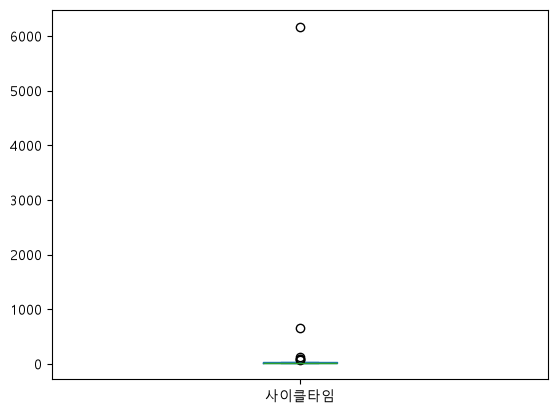

In [140]:
plt.rcParams["font.family"] = 'Malgun Gothic'
df['사이클타임'].plot(kind='box')
# plt.rcParams["font.family"] = 'Malgun Gothic'
plt.show()

In [141]:
# ── [실습 4] 이상치 제거 후 크기 비교 (사이클타임) ──────────────────────────3시 7분

In [142]:
정상 = df[~mask]

In [143]:
print(len(df), len(정상))                 # 202 196

202 196


In [144]:
print(round(df['사이클타임'].mean(), 2))  # 

64.75


In [145]:
print(round(정상['사이클타임'].mean(), 2))  # 27.28

27.28


In [146]:
# 실습5 3시 15분

In [147]:
# ── [실습 5] 경계값 보정 clipping (사이클타임) ──────────────────────────────
보정 = df['사이클타임'].clip(lower=lower, upper=upper)

In [148]:
lower, upper

(np.float64(-1.8874999999999922), np.float64(58.61249999999999))

In [149]:
print(round(보정.min(), 2), round(보정.max(), 2))   # 20.6 58.61

20.6 58.61


In [150]:
print(round(보정.mean(), 2))                        # 28.28

28.28


In [154]:
# 실습 6 3시 35분 제출

In [155]:
# ── [실습 6] 처리 전후 통계 비교 (실린더압력) ───────────────────────────────
Q1 = df['실린더압력'].quantile(0.25); Q3 = df['실린더압력'].quantile(0.75)
L = Q1 - 1.5 * (Q3 - Q1); U = Q3 + 1.5 * (Q3 - Q1)
m = (df['실린더압력'] < L) | (df['실린더압력'] > U)
채움 = df['실린더압력'].mask(m).fillna(df['실린더압력'].mask(m).median())
print(round(df['실린더압력'].mean(), 2))             # 234.31 (전)
print(round(df[~m]['실린더압력'].mean(), 2))         # 238.39 (제거)
print(round(df['실린더압력'].clip(L, U).mean(), 2))  # 235.31 (보정)
print(round(채움.mean(), 2))                        # 238.05 (채움)

234.31
238.39
235.31
238.05


In [156]:
# 실습7 3시 41분

In [157]:
# ── [실습 7] duplicated로 중복 찾기와 개수 ──────────────────────────────────
print(df.duplicated().sum())            # 2 (완전 중복)
print(df[df.duplicated()])              # 중복 행 확인
print(df.duplicated(keep=False).sum())  # 4 (겹친 행 모두)

2
      샷  실린더압력    주조압력  사이클타임  비스킷두께    형체력  상태
200   8  215.0  1038.0   20.9   11.0  258.0   0
201  89  235.0  1137.0   22.7   13.0  261.0   0
4


In [158]:
# 실습8 3시 45분

In [159]:
유일 = df.drop_duplicates()

In [160]:
print(len(df), len(유일))          # 202 200

202 200


In [161]:
print(유일.duplicated().sum())      # 0

0


In [162]:
print(len(df.drop_duplicates(subset=['샷'], keep='last')))  # 200

200


In [163]:
# ── [실습 9] reset_index로 인덱스 정리 ──────────────────────────────────────
정제 = df.drop_duplicates().reset_index(drop=True)
print(정제.index.min(), 정제.index.max())   # 0 199
print(len(정제))        

0 199
200


In [164]:
# 4시까지 실습 10하고 10분간 휴식, 제출

In [165]:
# ── [실습 10] 다른 현장(용접) 이상치·중복 종합 정제 — 캡스톤 ────────────────
wf = pd.read_csv(WD)
c = '통전전류'
q1, q3 = wf[c].quantile(0.25), wf[c].quantile(0.75)
lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
m = (wf[c] < lo) | (wf[c] > hi)
print(int(m.sum()), round(m.mean() * 100, 1))   # 24 14.8 (판정 0 불량과 대체로 일치)
wf[c] = wf[c].clip(lower=lo, upper=hi)
wf = wf.drop_duplicates().reset_index(drop=True)
wf.to_csv('cleaned_welding.csv', index=False)
print(len(wf))                                   # 158


24 14.8
158
